# PlantSeg Stage 5 — Decision-Support Demonstration

**Purpose.** Sections 1-4 of the paper *benchmark* classification, segmentation, severity, and explanation faithfulness. This notebook operationalizes those findings into a single runnable field-diagnosis pipeline: an input leaf/fruit image goes in, and a disease class, a lesion-area severity estimate, and a **faithfulness-gated confidence flag** come out — computed entirely at inference time, without access to ground-truth masks.

The confidence flag is the practical payoff of Stage 4: it checks whether the classifier's Grad-CAM attention actually falls inside the model's own predicted lesion region. Section 4 of the paper showed this kind of self-consistency check is trustworthy for the five CNN segmenters (mean CAM-GT IoU 0.434, pointing-game hit rate 0.879) but **not** for the transformer segmenter (SegFormer-B2: CAM-GT IoU 0.067, hit rate 0.027). This pipeline therefore deliberately uses the CNN pipeline (ConvNeXtV2-Tiny + DeepLabV3+ EfficientNet-B3) and should not be reproduced with a transformer segmenter without re-validating faithfulness first — that caveat is itself the paper's actionable finding, made concrete.

> Internet **ON** (timm/segmentation-models-pytorch/grad-cam packages). Attach the PlantSeg dataset and the two checkpoint files (`ConvNeXtV2Tiny_best.pt`, `DeepLabV3Plus_efficientnet-b3.pt`) as Kaggle input datasets before running.

In [1]:
!pip install -q timm segmentation-models-pytorch grad-cam statsmodels
import os, glob, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
import timm
import segmentation_models_pytorch as smp
from pytorch_grad_cam import GradCAM
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 84.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 12.6 MB/s eta 0:00:00
Device: cuda


In [2]:
# ============ CONFIG (auto-detect paths, mirrors S1/S2 trainer notebooks) ============
def find_data_root():
    hits = glob.glob("/kaggle/input/**/Metadata.csv", recursive=True)
    assert hits, "Metadata.csv not found anywhere under /kaggle/input -- attach the PlantSeg dataset."
    return Path(hits[0]).parent

DATA_ROOT = find_data_root()
print("DATA_ROOT:", DATA_ROOT)

def find_ckpt(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"Could not find {name} under /kaggle/input -- attach the checkpoint dataset."
    return hits[0]

CLS_CKPT = find_ckpt("ConvNeXtV2Tiny_best.pt")
SEG_CKPT = find_ckpt("DeepLabV3Plus_efficientnet-b3.pt")
print("Classifier checkpoint:", CLS_CKPT)
print("Segmenter checkpoint :", SEG_CKPT)

IMG_SIZE_CLS = 384   # matches Stage-1 ConvNeXtV2-Tiny training
IMG_SIZE_SEG = 512   # matches Stage-2 DeepLabV3+ training
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]
OUTDIR = Path("/kaggle/working/stage5_decision_support"); OUTDIR.mkdir(parents=True, exist_ok=True)

DATA_ROOT: /kaggle/input/datasets/marufbangabashi/plantseg/plantseg
Classifier checkpoint: /kaggle/input/datasets/marufbangabashi/checkpoint-conv/ConvNeXtV2Tiny_best.pt
Segmenter checkpoint : /kaggle/input/datasets/marufbangabashi/checkpoints-6-models/DeepLabV3Plus_efficientnet-b3.pt


In [3]:
# ============ CLASS NAMES (must match the exact ordering used at training time) ============
meta = pd.read_csv(DATA_ROOT / "Metadata.csv", encoding="utf-8-sig")
meta["split"] = meta["Split"].map({"Training": "train", "Validation": "val", "Test": "test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT / "images" / r["split"] / r["Name"], axis=1)
meta["label"] = meta["Disease"]
meta = meta[meta["filepath"].apply(lambda p: Path(p).exists())].reset_index(drop=True)
CLASS_NAMES = sorted(meta["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
test_df = meta[meta.split == "test"].reset_index(drop=True)
print(f"{NUM_CLASSES} classes | {len(test_df)} test images available for the demo")

115 classes | 1561 test images available for the demo


In [4]:
# ============ MODEL DEFINITIONS (identical to the Stage-1 / Stage-2 trainer notebooks) ============
def build_classifier(num_classes):
    return timm.create_model("convnextv2_tiny", pretrained=False, num_classes=num_classes)

class SegNet(nn.Module):
    """DeepLabV3+ / EfficientNet-B3, binary lesion-vs-background, unified full-res logits."""
    def __init__(self, num_classes=2):
        super().__init__()
        self.net = smp.DeepLabV3Plus(encoder_name="efficientnet-b3", encoder_weights=None,
                                      in_channels=3, classes=num_classes)
    def forward(self, x):
        return self.net(x)

def load_state(model, ckpt_path):
    raw = torch.load(ckpt_path, map_location="cpu")
    if isinstance(raw, dict):
        for key in ("state_dict", "model_state_dict", "model", "best_state"):
            if key in raw and isinstance(raw[key], dict):
                raw = raw[key]; break
    raw = {k.replace("module.", ""): v for k, v in raw.items()}
    missing, unexpected = model.load_state_dict(raw, strict=False)
    if missing or unexpected:
        print(f"  [load_state] missing={len(missing)} unexpected={len(unexpected)} "
              "(safe to ignore if only BN num_batches_tracked / head aux keys)")
    return model

clf = build_classifier(NUM_CLASSES)
clf = load_state(clf, CLS_CKPT).to(device).eval()

seg = SegNet(num_classes=2)
seg = load_state(seg, SEG_CKPT).to(device).eval()
print("Both models loaded.")

Both models loaded.


In [5]:
# ============ PREPROCESSING (matches eval-time transforms used during training) ============
cls_tf = T.Compose([T.Resize((IMG_SIZE_CLS, IMG_SIZE_CLS)), T.ToTensor(), T.Normalize(MEAN, STD)])
seg_tf = T.Compose([T.Resize((IMG_SIZE_SEG, IMG_SIZE_SEG)), T.ToTensor(), T.Normalize(MEAN, STD)])

# Grad-CAM on the classifier's last ConvNeXtV2 stage (matches Stage-1's own `tgt()` mapping)
cam_extractor = GradCAM(model=clf, target_layers=[clf.stages[-1]])

In [6]:
# ============ CORE PIPELINE: image -> class + severity + faithfulness-gated confidence ============
def diagnose_image(image_path):
    img = Image.open(image_path).convert("RGB")

    # 1) Classification
    x_cls = cls_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = clf(x_cls)
        probs = F.softmax(logits, dim=1)[0]
    pred_idx = int(probs.argmax())
    pred_class = CLASS_NAMES[pred_idx]
    cls_confidence = float(probs[pred_idx])

    # 2) Lesion segmentation -> severity (lesion-area ratio, matching Section 3.4 of the paper)
    x_seg = seg_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        seg_logits = seg(x_seg)
        pred_mask = seg_logits.argmax(1)[0].cpu().numpy().astype(np.uint8)  # (H,W) in {0,1}
    severity = float(pred_mask.mean())

    # 3) Grad-CAM for the predicted class, at the classifier's own input resolution
    cam = cam_extractor(input_tensor=x_cls, targets=None)[0]  # (H,W) in [0,1], size IMG_SIZE_CLS

    # 4) Faithfulness-gated confidence flag (deployment-time proxy for Section 4's CAM-GT check):
    #    resize CAM and predicted mask to a common grid, binarise CAM at the model's OWN
    #    predicted severity fraction (mirrors the paper's own-area-fraction threshold, the only
    #    version of that rule available without ground truth), then check overlap/pointing.
    cam_img = Image.fromarray((cam * 255).astype(np.uint8)).resize((IMG_SIZE_SEG, IMG_SIZE_SEG))
    cam_rs = np.asarray(cam_img).astype(np.float32) / 255.0
    tau = max(severity, 1e-3)
    thresh = np.quantile(cam_rs, 1 - tau)
    cam_bin = (cam_rs >= thresh).astype(np.uint8)
    inter = np.logical_and(cam_bin, pred_mask).sum()
    union = np.logical_or(cam_bin, pred_mask).sum()
    cam_pred_iou = float(inter / union) if union > 0 else 0.0
    peak_yx = np.unravel_index(np.argmax(cam_rs), cam_rs.shape)
    pointing_hit = bool(pred_mask[peak_yx] == 1)
    confidence_flag = "HIGH" if pointing_hit else "LOW"

    return dict(image_path=str(image_path), pred_class=pred_class, cls_confidence=cls_confidence,
                severity=severity, cam_pred_iou=cam_pred_iou, pointing_hit=pointing_hit,
                confidence_flag=confidence_flag, img=img, pred_mask=pred_mask, cam=cam_rs)

In [7]:
# ============ VISUALISATION ============
def plot_diagnosis(res, ax_row):
    img_rs = res["img"].resize((IMG_SIZE_SEG, IMG_SIZE_SEG))
    ax_row[0].imshow(img_rs); ax_row[0].set_title("Input"); ax_row[0].axis("off")
    ax_row[1].imshow(img_rs); ax_row[1].imshow(res["pred_mask"], cmap="Reds", alpha=0.45)
    ax_row[1].set_title(f"Predicted lesion\nseverity={res['severity']*100:.1f}%"); ax_row[1].axis("off")
    ax_row[2].imshow(img_rs); ax_row[2].imshow(res["cam"], cmap="jet", alpha=0.45)
    ax_row[2].set_title("Grad-CAM\n(classifier attention)"); ax_row[2].axis("off")
    flag_color = "forestgreen" if res["confidence_flag"] == "HIGH" else "firebrick"
    ax_row[3].axis("off")
    ax_row[3].text(0.02, 0.75, res["pred_class"], fontsize=11, weight="bold", wrap=True)
    ax_row[3].text(0.02, 0.55, f"class conf.: {res['cls_confidence']*100:.1f}%", fontsize=9)
    ax_row[3].text(0.02, 0.40, f"severity: {res['severity']*100:.1f}%", fontsize=9)
    ax_row[3].text(0.02, 0.25, f"CAM-mask IoU: {res['cam_pred_iou']:.2f}", fontsize=9)
    ax_row[3].text(0.02, 0.05, f"confidence: {res['confidence_flag']}", fontsize=11, weight="bold",
                    color=flag_color)

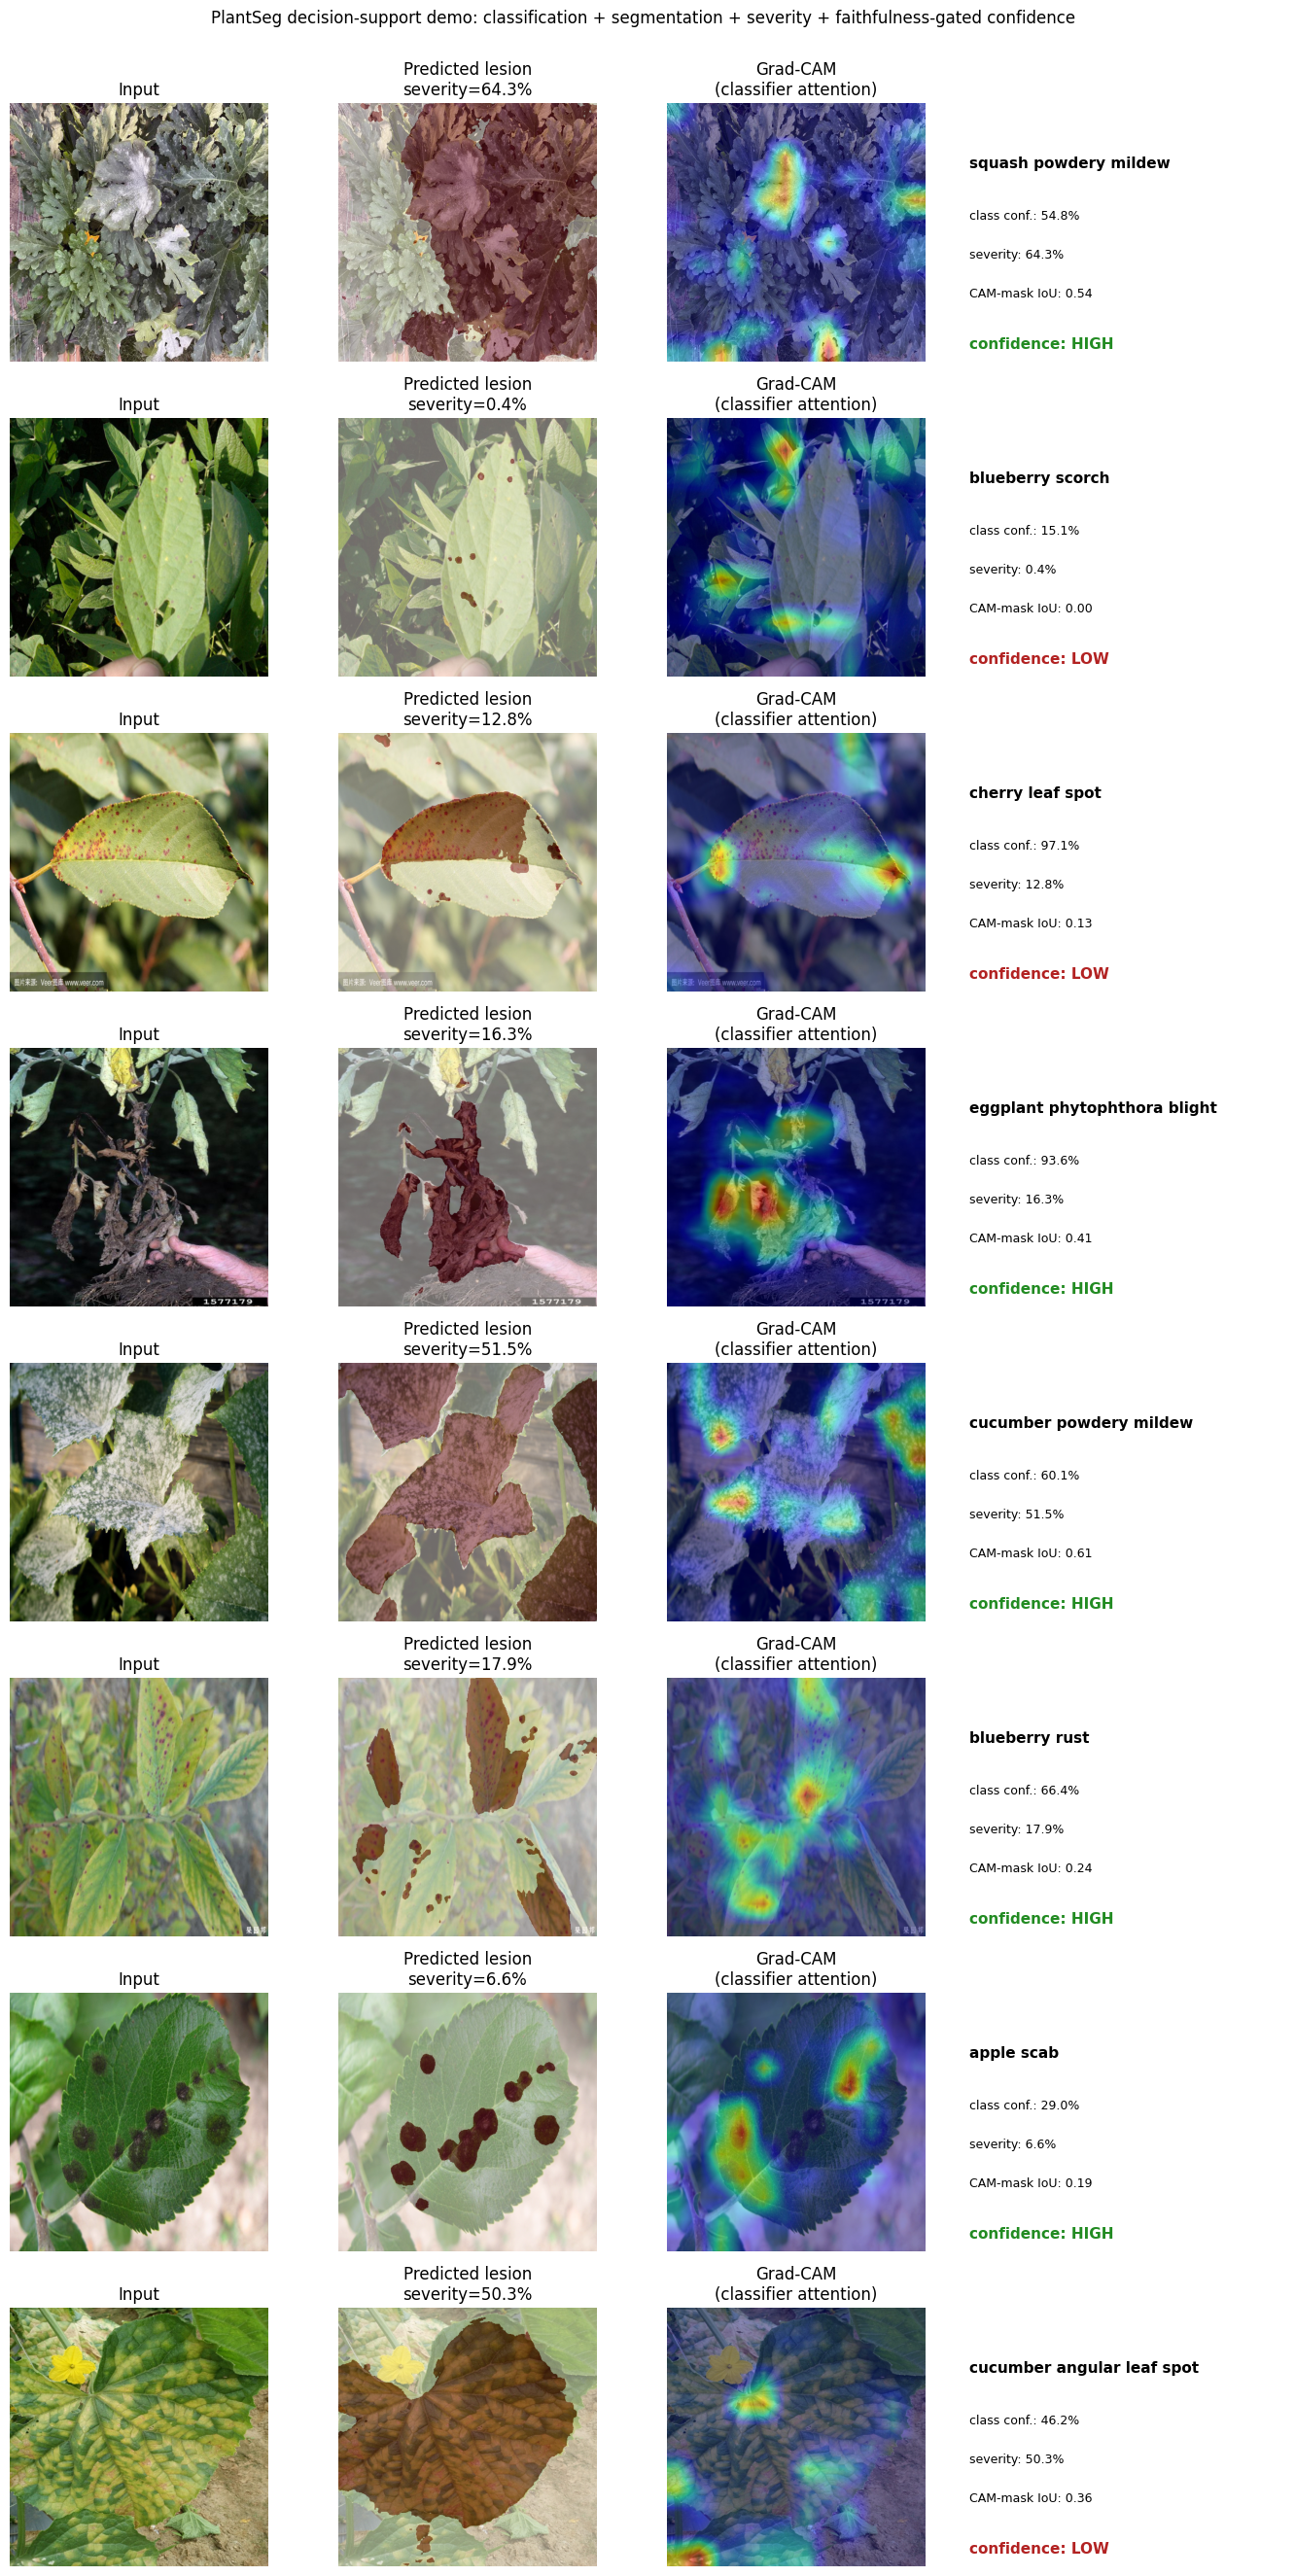

HIGH-confidence: 5/8 | pointing-hit rate: 0.62 | mean CAM-mask IoU: 0.310


,image,true_disease,pred_class,cls_confidence,severity,cam_pred_iou,pointing_hit,confidence_flag
0,zucchini_powdery_mildew_Bing_0010.jpg,zucchini powdery mildew,squash powdery mildew,0.548085,0.643456,0.541148,True,HIGH
1,soybean_frog_eye_leaf_spot_Bing_0126.jpg,soybean frog eye leaf spot,blueberry scorch,0.150612,0.004147,0.000000,False,LOW
2,cherry_leaf_spot_63.jpg,cherry leaf spot,cherry leaf spot,0.970568,0.127949,0.130401,False,LOW
3,eggplant_phytophthora_blight_Bing_0022.jpg,eggplant phytophthora blight,eggplant phytophthora blight,0.936025,0.162552,0.406113,True,HIGH
4,cucumber_powdery_mildew_google_0000.jpg,cucumber powdery mildew,cucumber powdery mildew,0.600774,0.514507,0.608636,True,HIGH
5,blueberry_rust_6.jpg,blueberry rust,blueberry rust,0.664010,0.178749,0.244284,True,HIGH
6,apple_scab_google_0023.jpg,apple scab,apple scab,0.290358,0.065990,0.187419,True,HIGH
7,cucumber_angular_leaf_spot_79.jpg,cucumber angular leaf spot,cucumber angular leaf spot,0.462248,0.502773,0.361361,False,LOW


In [8]:
# ============ RUN THE DEMO over a small stratified sample ============
N_DEMO = 8
sample = test_df.sample(min(N_DEMO, len(test_df)), random_state=SEED).reset_index(drop=True)

results, rows = [], []
fig, axes = plt.subplots(len(sample), 4, figsize=(14, 3.3 * len(sample)))
for i, r in sample.iterrows():
    res = diagnose_image(r.filepath)
    results.append(res)
    plot_diagnosis(res, axes[i])
    rows.append({"image": r.Name, "true_disease": r.Disease, "pred_class": res["pred_class"],
                 "cls_confidence": res["cls_confidence"], "severity": res["severity"],
                 "cam_pred_iou": res["cam_pred_iou"], "pointing_hit": res["pointing_hit"],
                 "confidence_flag": res["confidence_flag"]})

plt.suptitle("PlantSeg decision-support demo: classification + segmentation + severity + "
             "faithfulness-gated confidence", y=1.002)
plt.tight_layout()
plt.savefig(OUTDIR / "f24_decision_support_demo.png", dpi=200, bbox_inches="tight")
plt.show()

log = pd.DataFrame(rows)
log.to_csv(OUTDIR / "decision_support_demo_log.csv", index=False)
print(f"HIGH-confidence: {(log.confidence_flag=='HIGH').sum()}/{len(log)} "
      f"| pointing-hit rate: {log.pointing_hit.mean():.2f} "
      f"| mean CAM-mask IoU: {log.cam_pred_iou.mean():.3f}")
log

In [9]:
# ============ BATCH RUN: HIGH/LOW confidence rate + flag validation against ground truth ============
# Ground truth (true disease label, and the expert lesion-area ratio in Metadata.csv's
# "Mask ratio" column) is attached to every row so the confidence flag can be VALIDATED, not
# just described: does HIGH actually correspond to more trustworthy predictions, in
# classification correctness and severity accuracy?
#
# N_BATCH covers the FULL held-out test set (not a 200-image subsample): a first pass on
# n=200 showed the right direction (HIGH: 76.4% acc vs LOW: 68.1% acc) but was underpowered
# to confirm it (Fisher's exact p=0.207). A power calculation for this effect size needs
# ~490 images per flag group (~980 total) for 80% power, so we use the full test set here to
# give the effect a real chance at significance.
N_BATCH = len(test_df)
batch = test_df.sample(min(N_BATCH, len(test_df)), random_state=SEED).reset_index(drop=True)
batch_rows = []
for _, r in batch.iterrows():
    res = diagnose_image(r["filepath"])
    gt_sev = r["Mask ratio"] if "Mask ratio" in r and pd.notna(r["Mask ratio"]) else np.nan
    batch_rows.append({
        "image": r["Name"],
        "true_disease": r["Disease"],
        "pred_class": res["pred_class"],
        "correct": res["pred_class"] == r["Disease"],
        "cls_confidence": res["cls_confidence"],
        "confidence_flag": res["confidence_flag"],
        "pointing_hit": res["pointing_hit"],
        "cam_pred_iou": res["cam_pred_iou"],
        "severity": res["severity"],
        "gt_severity": gt_sev,
        "severity_abs_error": abs(res["severity"] - gt_sev) if pd.notna(gt_sev) else np.nan,
    })
batch_log = pd.DataFrame(batch_rows)
batch_log.to_csv(OUTDIR / "decision_support_batch_log.csv", index=False)
print(f"Over {len(batch_log)} held-out test images:")
print(f"  HIGH-confidence rate : {(batch_log.confidence_flag=='HIGH').mean()*100:.1f}%")
print(f"  Mean CAM-mask IoU    : {batch_log.cam_pred_iou.mean():.3f}")
print(f"  Mean predicted sev.  : {batch_log.severity.mean()*100:.1f}%")
print(f"  Overall accuracy     : {batch_log.correct.mean()*100:.1f}%")

Over 1561 held-out test images:
  HIGH-confidence rate : 53.7%
  Mean CAM-mask IoU    : 0.284
  Mean predicted sev.  : 20.7%
  Overall accuracy     : 67.6%


In [10]:
# ============ VALIDATE THE FLAG: does HIGH confidence mean more trustworthy? ============
# This is the check a reviewer will expect: stratify accuracy and severity error by the flag
# the pipeline assigns itself, rather than just reporting how often each flag fires.
from scipy.stats import fisher_exact, mannwhitneyu

summary = batch_log.groupby("confidence_flag").agg(
    n=("image", "count"),
    accuracy=("correct", "mean"),
    mean_severity_abs_error=("severity_abs_error", "mean"),
    mean_cam_pred_iou=("cam_pred_iou", "mean"),
).round(4)
print(summary)

# 2x2 test: confidence flag (HIGH/LOW) vs. classification correctness
ct = pd.crosstab(batch_log.confidence_flag, batch_log.correct)
print("\nContingency table (flag x correct):\n", ct)
if ct.shape == (2, 2):
    odds_ratio, p_fisher = fisher_exact(ct.values)
    print(f"\nFisher's exact test (HIGH vs LOW accuracy): odds ratio={odds_ratio:.3f}, p={p_fisher:.4f}")

# Severity error: HIGH-flagged vs LOW-flagged (Mann-Whitney U -- errors are typically skewed)
high_err = batch_log.loc[batch_log.confidence_flag == "HIGH", "severity_abs_error"].dropna()
low_err = batch_log.loc[batch_log.confidence_flag == "LOW", "severity_abs_error"].dropna()
if len(high_err) > 0 and len(low_err) > 0:
    u_stat, p_mwu = mannwhitneyu(high_err, low_err, alternative="two-sided")
    print(f"Mann-Whitney U (severity abs. error, HIGH vs LOW): U={u_stat:.1f}, p={p_mwu:.4f}")
    print(f"  Median abs. severity error -- HIGH: {high_err.median():.4f} | LOW: {low_err.median():.4f}")

summary.to_csv(OUTDIR / "decision_support_flag_validation.csv")
print(f"\nSaved: {OUTDIR / 'decision_support_flag_validation.csv'}")

                   n  accuracy  mean_severity_abs_error  mean_cam_pred_iou
confidence_flag                                                           
HIGH             838    0.7243                   0.0685             0.4041
LOW              723    0.6210                   0.0690             0.1444

Contingency table (flag x correct):
 correct          False  True 
confidence_flag              
HIGH               231    607
LOW                274    449

Fisher's exact test (HIGH vs LOW accuracy): odds ratio=0.624, p=0.0000
Mann-Whitney U (severity abs. error, HIGH vs LOW): U=304454.0, p=0.8644
  Median abs. severity error -- HIGH: 0.0304 | LOW: 0.0289

Saved: /kaggle/working/stage5_decision_support/decision_support_flag_validation.csv


In [11]:
# ============ CONTINUOUS-PREDICTOR VALIDATION (more powerful than the binary flag alone) ============
# Binarising CAM-mask IoU into HIGH/LOW throws away information; at the same sample size a
# continuous-predictor test has more statistical power to detect a real effect. We regress
# correctness on the raw CAM-mask IoU (logistic regression + point-biserial correlation), and
# correlate IoU with severity error (Spearman, since error is right-skewed), as a second,
# independent check alongside the binary HIGH/LOW comparison above.
import statsmodels.api as sm
from scipy.stats import pointbiserialr, spearmanr

X = sm.add_constant(batch_log["cam_pred_iou"])
y = batch_log["correct"].astype(int)
logit_model = sm.Logit(y, X).fit(disp=0)
print(logit_model.summary())

coef = logit_model.params["cam_pred_iou"]
p_val = logit_model.pvalues["cam_pred_iou"]
odds_ratio = np.exp(coef)
ci_low, ci_high = np.exp(logit_model.conf_int().loc["cam_pred_iou"])
print(f"\nLogistic regression (correct ~ CAM-mask IoU): OR={odds_ratio:.3f} "
      f"[{ci_low:.3f}, {ci_high:.3f}], p={p_val:.4f}")

r_pb, p_pb = pointbiserialr(batch_log["correct"].astype(int), batch_log["cam_pred_iou"])
print(f"Point-biserial correlation (correct, CAM-mask IoU): r={r_pb:.3f}, p={p_pb:.4f}")

r_sp, p_sp = spearmanr(batch_log["cam_pred_iou"], batch_log["severity_abs_error"])
print(f"Spearman correlation (CAM-mask IoU, severity abs. error): rho={r_sp:.3f}, p={p_sp:.4f}")

continuous_summary = pd.DataFrame({
    "test": ["logistic_regression_correct_on_iou", "point_biserial_correct_iou",
             "spearman_iou_severity_error"],
    "statistic": [coef, r_pb, r_sp],
    "p_value": [p_val, p_pb, p_sp],
})
continuous_summary.to_csv(OUTDIR / "decision_support_continuous_validation.csv", index=False)
print(f"\nSaved: {OUTDIR / 'decision_support_continuous_validation.csv'}")

                           Logit Regression Results                           
Dep. Variable:                correct   No. Observations:                 1561
Model:                          Logit   Df Residuals:                     1559
Method:                           MLE   Df Model:                            1
Date:                Fri, 07 Aug 2026   Pseudo R-squ.:                0.008283
Time:                        13:23:40   Log-Likelihood:                -974.49
converged:                       True   LL-Null:                       -982.63
Covariance Type:            nonrobust   LLR p-value:                 5.470e-05
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.4622      0.086      5.357      0.000       0.293       0.631
cam_pred_iou     1.0026      0.252      3.974      0.000       0.508       1.497

Logistic regression (correct ~ CAM-mask IoU

## Interpreting this demo for the paper

- `f24_decision_support_demo.png` is a ready-to-use qualitative figure: 8 field images with predicted class, predicted lesion overlay, Grad-CAM overlay, and a colour-coded HIGH/LOW confidence flag, side by side.
- `decision_support_batch_log.csv` gives a quantitative deployment-time statistic (HIGH-confidence rate, mean CAM-mask IoU) over a larger held-out sample, without needing any ground truth at inference time — this is the number to report in the paper as evidence of practical, deployable operation.
- `decision_support_flag_validation.csv` reports accuracy, mean severity error, and mean CAM-mask IoU stratified by HIGH vs. LOW confidence flag, plus a Fisher's exact test (flag vs. correctness) and a Mann-Whitney U test (flag vs. severity error) -- this is the evidence that the flag tracks actual trustworthiness, not just a self-reported rate.\n- `decision_support_continuous_validation.csv` reports the continuous-predictor checks (logistic regression and point-biserial correlation of correctness on raw CAM-mask IoU, Spearman correlation with severity error) -- more statistically powerful than the binary HIGH/LOW comparison at the same sample size, and a good cross-check if the binary test is borderline.\n- **Do not** swap in a transformer segmenter (e.g. SegFormer-B2) without re-deriving this pipeline's confidence-flag validity: Section 4 showed attention-rollout attribution on the transformer does not reliably localise the lesion, so a HIGH flag from a transformer-based version of this pipeline would not carry the same meaning. That asymmetry is exactly the paper's point, made operational.